# 05 · Churn-risk model
**Business question:** *Which customers are likely to stop buying in the next 12 months?*

Churn is **inferred** (no order in the next 365 days) — customers never formally leave. Why 365 not 180 days: many accounts are seasonal; at a December cutoff 54% of customers are silent for 180 days but many return for the next peak. Training cutoff Dec-2010 is seasonally matched to today's Dec-2011 scoring date.

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

In [2]:
pd.read_csv(T / 'churn_model_comparison.csv')

,setting,model,roc_auc,pr_auc,brier,base_rate,top_decile_churn_rate,top_decile_lift
0,180d label | in-season CV (Dec-2010),baseline: recency only,0.693,0.712,NaN,0.536,0.799,1.491
1,180d label | in-season CV (Dec-2010),baseline: BG/NBD 1 - P(alive),0.379,0.530,0.531,0.536,0.607,1.133
2,180d label | out-of-time (Jun-2011),baseline: recency only,0.730,0.643,NaN,0.430,0.762,1.773
3,180d label | out-of-time (Jun-2011),baseline: BG/NBD 1 - P(alive),0.480,0.494,0.369,0.430,0.581,1.353
4,180d label | in-season CV (Dec-2010),logistic_regression,0.784,0.769,0.185,0.536,0.827,1.544
5,180d label | out-of-time (Jun-2011),logistic_regression,0.783,0.694,0.206,0.430,0.769,1.789
6,180d label | in-season CV (Dec-2010),gradient_boosting,0.774,0.762,0.189,0.536,0.855,1.597
7,180d label | out-of-time (Jun-2011),gradient_boosting,0.776,0.690,0.205,0.430,0.775,1.805
8,365d label | in-season CV (Dec-2010) [PRIMARY],baseline: recency only,0.714,0.589,NaN,0.366,0.704,1.924
9,365d label | in-season CV (Dec-2010) [PRIMARY],baseline: BG/NBD 1 - P(alive),0.375,0.379,0.362,0.366,0.464,1.269


**Read-out**
* Logistic regression: CV ROC-AUC **0.785** vs 0.714 for 'days since last order' alone. Gradient boosting adds nothing, so the interpretable model is kept (pre-declared rule).
* The 180-day variant holds its AUC out-of-time (0.78 at a June cutoff) → the ranking generalises across seasons.
* **BG/NBD P(alive) ranks churn worse than random (AUC ~0.38).** It assigns P(alive)=1 to one-time buyers — who churn most. It is therefore *not* used for risk.

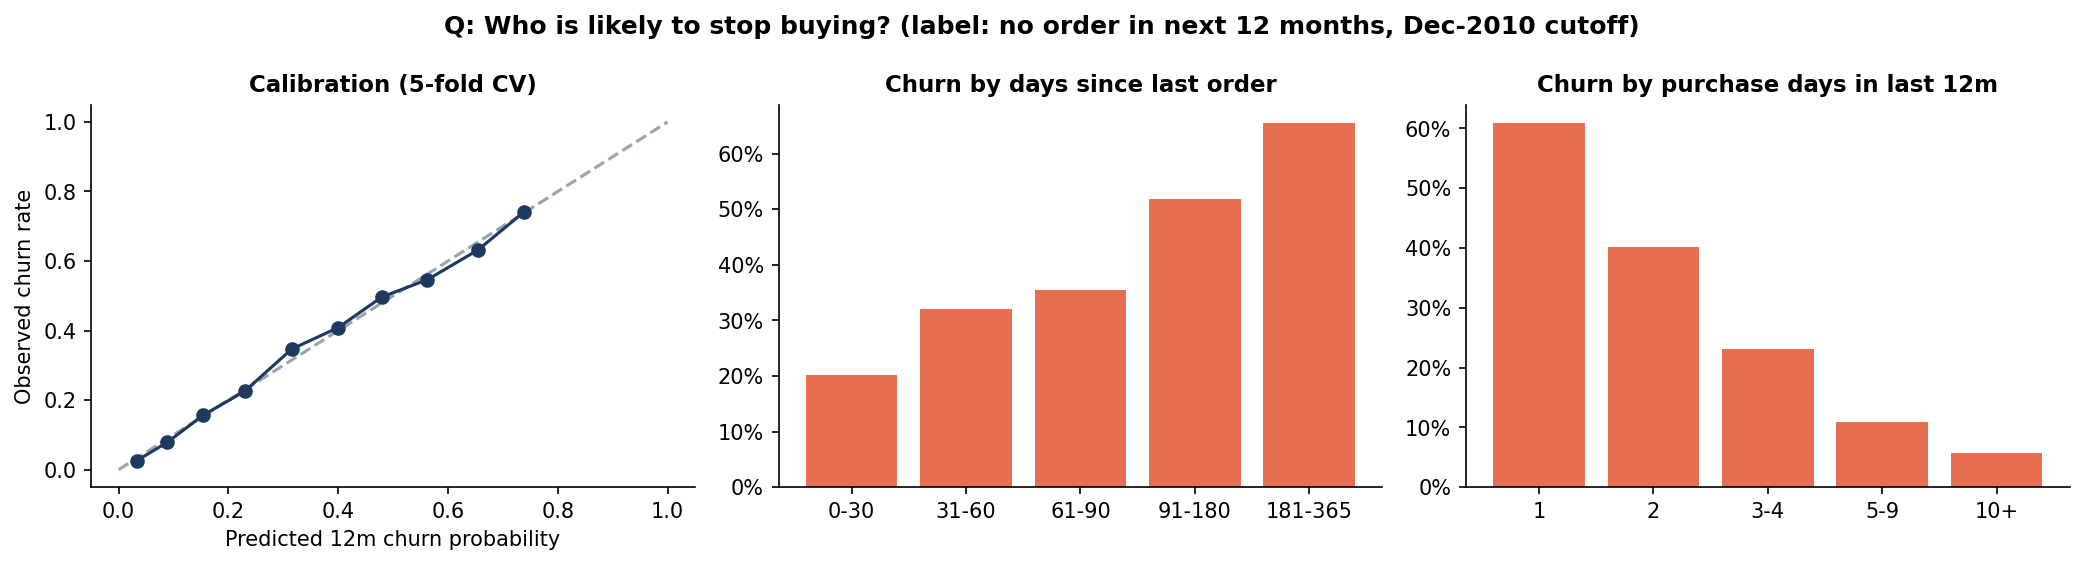

In [3]:
fig('09_churn_model_diagnostics')

In [4]:
pd.read_csv(T / 'churn_calibration.csv')

,bin,mean_predicted,observed_rate,customers
0,0,0.033,0.026,422
1,1,0.088,0.078,421
2,2,0.154,0.157,421
3,3,0.230,0.226,421
4,4,0.315,0.347,421
5,5,0.400,0.409,421
6,6,0.479,0.496,421
7,7,0.562,0.546,421
8,8,0.655,0.632,421
9,9,0.739,0.742,422


Predicted probabilities match observed churn within ~3 percentage points in every decile. This matters: probabilities are multiplied by revenue to get revenue at risk.

In [5]:
pd.read_csv(T / 'churn_lr_coefficients.csv')

,feature,coef_standardised,note
0,avg_gap_days,1.495,"recency_days, avg_gap_days and overdue_ratio a..."
1,tenure_capped,-1.128,"recency_days, avg_gap_days and overdue_ratio a..."
2,overdue_ratio,1.005,"recency_days, avg_gap_days and overdue_ratio a..."
3,revenue_w,-0.435,"recency_days, avg_gap_days and overdue_ratio a..."
4,orders_w,0.157,"recency_days, avg_gap_days and overdue_ratio a..."
5,purchase_days_w,0.152,"recency_days, avg_gap_days and overdue_ratio a..."
6,recency_days,-0.119,"recency_days, avg_gap_days and overdue_ratio a..."
7,gap_cv,0.103,"recency_days, avg_gap_days and overdue_ratio a..."
8,momentum,-0.081,"recency_days, avg_gap_days and overdue_ratio a..."
9,distinct_products_w,-0.071,"recency_days, avg_gap_days and overdue_ratio a..."


In [6]:
pd.read_csv(T / 'churn_model_card.csv', index_col=0)

,value
chosen_model,logistic_regression
label,no order in next 365 days
train_cutoff,2010-12-09
train_customers,4212
train_churn_rate,0.3658594491927825
cv_roc_auc,0.7851021292217149
cv_brier,0.17967799507704915
scored_customers,4250
scoring_population,customers with >=1 order in the 365 days to sn...
mean_score_now,0.3345686214875831


## What should management do differently?
1. **Trigger outreach from each customer's own rhythm**, not a fixed 'inactive for 90 days' rule. Buying cadence and tenure are the strongest risk signals.
2. **The first repeat purchases are decisive:** customers with one purchase day in a year churn at 61%; with 5–9 purchase days, 11%.
3. **Refresh scores monthly** and track the model's calibration; retrain each December (seasonal alignment).